# PRAKTIKUM DATA MINING
## Association Rule Mining (Market Basket Analysis)
### Hands-on Langkah Praktikum Sesuai Modul (Bagian 4.1 - 4.8)

- **Mata Kuliah**: Praktikum Data Mining
- **Topik**: Association Rule Mining Menggunakan Algoritma Apriori & FP-Growth
- **Dataset**: 60 Transaksi Toko Kelontong (12 Item Sintetis Realistis)
- **Pustaka Utama**: `mlxtend` (TransactionEncoder, apriori, fpgrowth, association_rules), `pandas`, `matplotlib`
- **Referensi Modul**: *Modul Praktikum Data Mining — Association Rule Mining (Market Basket Analysis)*


---
## 4.1 Persiapan Data Transaksi
Pada tahap ini, kita mengimpor library yang diperlukan: `pandas`, `numpy`, `TransactionEncoder`, `apriori`, `fpgrowth`, serta `association_rules` dari `mlxtend`.
Dataset yang digunakan berasal dari transaksi toko kelontong sebanyak 60 transaksi dengan 12 jenis item.


In [1]:
import pandas as pd
import numpy as np
import time
from collections import Counter
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Membaca dataset 60 transaksi
df_raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [x.split(', ') for x in df_raw['Items'].dropna()]

print('Jumlah transaksi:', len(transactions))
print('\n5 Transaksi Pertama:')
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')


Jumlah transaksi: 60

5 Transaksi Pertama:
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


### Memeriksa Frekuensi Kemunculan Tiap Item
Sebelum menjalankan algoritma frequent pattern mining, kita menganalisis distribusi kemunculan masing-masing item untuk memahami item apa saja yang paling dominan dan jarang dibeli.


In [2]:
cnt = Counter()
for t in transactions:
    cnt.update(t)

print(f"{'Item':15s} | {'Frekuensi':9s} | {'Support':7s}")
print("-" * 37)
for item, freq in cnt.most_common():
    sup = freq / len(transactions)
    print(f"{item:15s} : {freq:2d}         (support = {sup:.3f})")


Item            | Frekuensi | Support
-------------------------------------
Susu            : 19         (support = 0.317)
Roti            : 18         (support = 0.300)
Mie Instan      : 18         (support = 0.300)
Mentega         : 17         (support = 0.283)
Telur           : 15         (support = 0.250)
Sabun           : 15         (support = 0.250)
Gula            : 14         (support = 0.233)
Kopi            : 13         (support = 0.217)
Shampo          : 13         (support = 0.217)
Kecap           : 12         (support = 0.200)
Keju            :  6         (support = 0.100)
Teh             :  4         (support = 0.067)


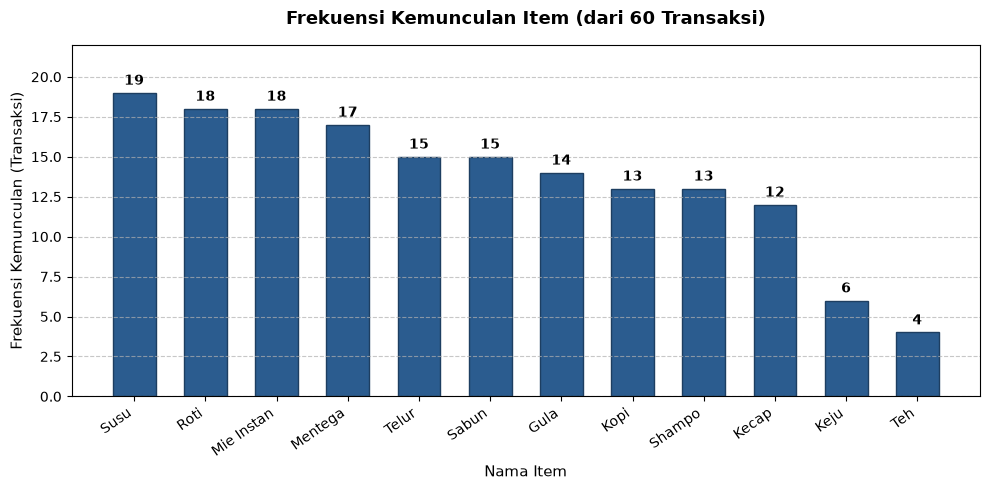

In [3]:
# Visualisasi Frekuensi Item (Gambar 2 Modul)
items_sorted = cnt.most_common()
items, freqs = zip(*items_sorted)

plt.figure(figsize=(10, 5))
bars = plt.bar(items, freqs, color='#2b5c8f', edgecolor='#1d3e61', width=0.6)
plt.title('Frekuensi Kemunculan Item (dari 60 Transaksi)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Nama Item', fontsize=11)
plt.ylabel('Frekuensi Kemunculan (Transaksi)', fontsize=11)
plt.ylim(0, 22)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f'{int(yval)}', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


---
## 4.2 Encoding Data Transaksi ke Format One-Hot
Algoritma Apriori dan FP-Growth pada pustaka `mlxtend` memerlukan data dalam bentuk matriks one-hot boolean (`True`/`False`), di mana baris menunjukkan transaksi dan kolom menunjukkan keberadaan item.


In [4]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print('\n5 Baris Pertama Matriks One-Hot:')
display(df.iloc[:5, :6])


Ukuran matriks one-hot: (60, 12)

5 Baris Pertama Matriks One-Hot:


,Gula,Kecap,Keju,Kopi,Mentega,Mie Instan
0,True,False,False,True,False,False
1,True,False,False,True,False,False
2,False,False,False,False,True,False
3,False,False,False,False,False,True
4,False,False,True,False,False,False


---
## 4.3 Mencari Frequent Itemset dengan Algoritma Apriori
Dengan ambang batas minimum support `min_support = 0.15` (itemset harus muncul minimal pada 9 dari 60 transaksi atau 15%), kita jalankan algoritma Apriori.


In [5]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False).reset_index(drop=True)

print('Jumlah frequent itemset:', len(freq_apriori))
display(freq_apriori)


Jumlah frequent itemset: 17


,support,itemsets
0,0.316667,frozenset({Susu})
1,0.300000,frozenset({Roti})
2,0.300000,frozenset({Mie Instan})
3,0.283333,frozenset({Mentega})
4,0.250000,frozenset({Sabun})
5,0.250000,frozenset({Telur})
6,0.233333,frozenset({Gula})
7,0.216667,frozenset({Shampo})
8,0.216667,frozenset({Kopi})
9,0.216667,"frozenset({Roti, Susu})"


---
## 4.4 Membentuk Aturan Asosiasi
Dari frequent itemset yang telah diperoleh, kita membangun aturan asosiasi ($X ightarrow Y$) menggunakan metrik evaluasi `confidence` dengan ambang batas `min_confidence = 0.5`. Hasil aturan kemudian diurutkan berdasarkan `lift` tertinggi.


In [6]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print('Jumlah aturan asosiasi:', len(rules))
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']
display(rules[cols].round(3))

# Simpan ke CSV untuk referensi pengerjaan tugas
rules.to_csv('rules.csv', index=False)


Jumlah aturan asosiasi: 18


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,"frozenset({Mentega, Susu})",frozenset({Roti}),0.183,1.000,3.333,0.128,inf
1,frozenset({Roti}),"frozenset({Mentega, Susu})",0.183,0.611,3.333,0.128,2.100
2,frozenset({Mentega}),"frozenset({Roti, Susu})",0.183,0.647,2.986,0.122,2.219
3,"frozenset({Roti, Susu})",frozenset({Mentega}),0.183,0.846,2.986,0.122,4.658
4,frozenset({Sabun}),frozenset({Shampo}),0.150,0.600,2.769,0.096,1.958
5,frozenset({Shampo}),frozenset({Sabun}),0.150,0.692,2.769,0.096,2.438
6,frozenset({Susu}),"frozenset({Roti, Mentega})",0.183,0.579,2.672,0.115,1.860
7,"frozenset({Roti, Mentega})",frozenset({Susu}),0.183,0.846,2.672,0.115,4.442
8,frozenset({Roti}),frozenset({Mentega}),0.217,0.722,2.549,0.132,2.580
9,frozenset({Mentega}),frozenset({Roti}),0.217,0.765,2.549,0.132,2.975


---
## 4.5 Visualisasi Hasil
Untuk mengevaluasi seluruh aturan secara menyeluruh, kita menampilkan:
1. **Scatter Plot Support vs Confidence** dengan ukuran dan warna bubble merepresentasikan nilai `Lift` (Gambar 3).
2. **Horizontal Bar Chart** 8 Aturan dengan Lift tertinggi (Gambar 4).


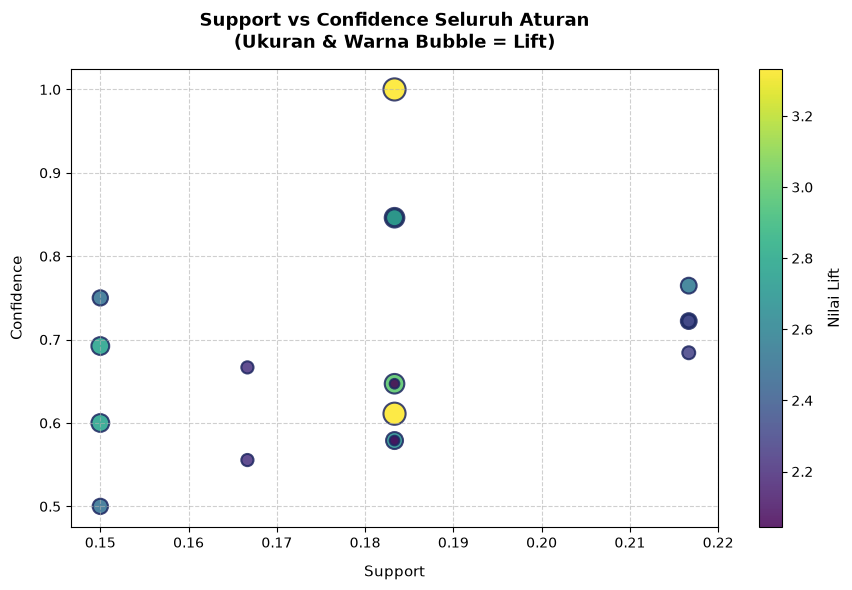

In [7]:
# Gambar 3: Scatter Plot Support vs Confidence (Bubble = Lift)
plt.figure(figsize=(9, 6))
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes, c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761', linewidth=1.5)
cbar = plt.colorbar(sc)
cbar.set_label('Nilai Lift', fontsize=11, labelpad=10)
plt.xlabel('Support', fontsize=11, labelpad=10)
plt.ylabel('Confidence', fontsize=11, labelpad=10)
plt.title('Support vs Confidence Seluruh Aturan\n(Ukuran & Warna Bubble = Lift)', fontsize=13, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


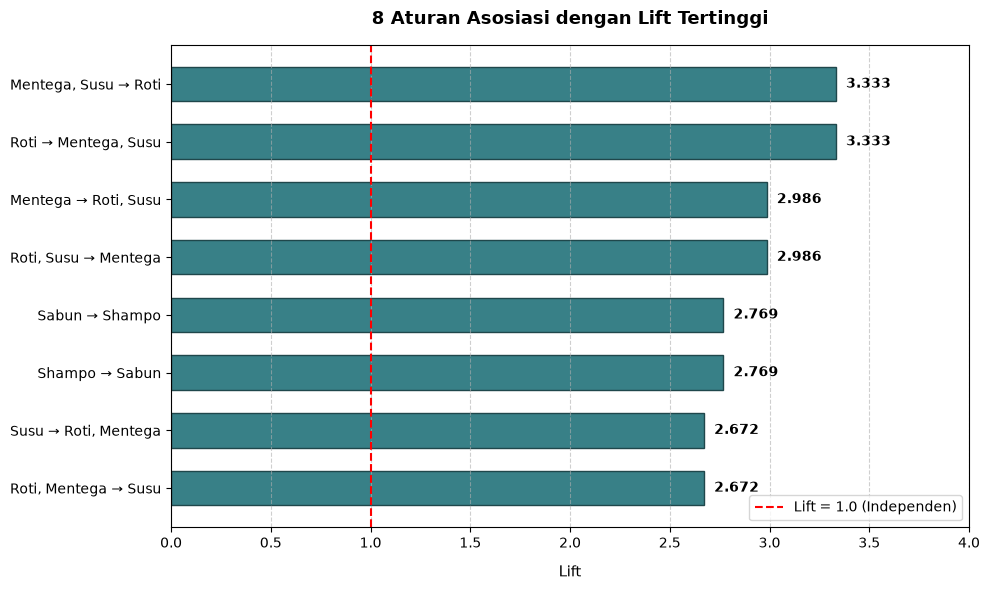

In [8]:
# Gambar 4: 8 Aturan Asosiasi dengan Lift Tertinggi
top8 = rules.head(8).copy()
labels = [f"{', '.join(list(a))} → {', '.join(list(c))}" for a, c in zip(top8['antecedents'], top8['consequents'])]
labels.reverse()
lifts = list(top8['lift'])
lifts.reverse()

plt.figure(figsize=(10, 6))
bars = plt.barh(labels, lifts, color='#388087', edgecolor='#1f474b', height=0.6)
plt.axvline(x=1.0, color='red', linestyle='--', linewidth=1.5, label='Lift = 1.0 (Independen)')
plt.title('8 Aturan Asosiasi dengan Lift Tertinggi', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Lift', fontsize=11, labelpad=10)
plt.xlim(0, 4.0)
for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 0.05, bar.get_y() + bar.get_height()/2.0, f'{xval:.3f}', ha='left', va='center', fontsize=10, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---
## 4.6 Interpretasi Bisnis dari Aturan Terpilih
Berdasarkan hasil aturan asosiasi yang ditemukan, terdapat 3 kelompok pola belanja yang sangat menonjol:
1. **Kelompok Sarapan**: $\{\text{Mentega, Susu}\} \rightarrow \{\text{Roti}\}$ ($Lift = 3.333, Confidence = 100\%$)
   - Rekomendasi: Penataan rak berdekatan di lorong bahan sarapan atau pembuatan paket bundling "Paket Sarapan Praktis".
2. **Kelompok Toiletries**: $\{\text{Sabun}\} \rightarrow \{\text{Shampo}\}$ ($Lift = 2.769, Confidence = 60\%$)
   - Rekomendasi: Planogram lorong mandi terintegrasi dan promo cross-selling (diskon shampo untuk pembelian sabun tertentu).
3. **Kelompok Makanan Cepat Saji**: $\{\text{Kecap}\} \rightarrow \{\text{Mie Instan}\}$ ($Lift = 2.500, Confidence = 75\%$)
   - Rekomendasi: Penempatan botol kecap mini dekat rak mie instan serta rekomendasi otomatis add-to-cart pada aplikasi belanja.


---
## 4.7 Eksperimen: Pengaruh Nilai min_support
Pada tahap ini, kita mengamati pengaruh perubahan nilai `min_support` terhadap jumlah frequent itemset dan aturan asosiasi yang terbentuk.


In [9]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
itemset_counts = []
rule_counts = []

for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    itemset_counts.append(len(fi))
    rule_counts.append(len(r))
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')


min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


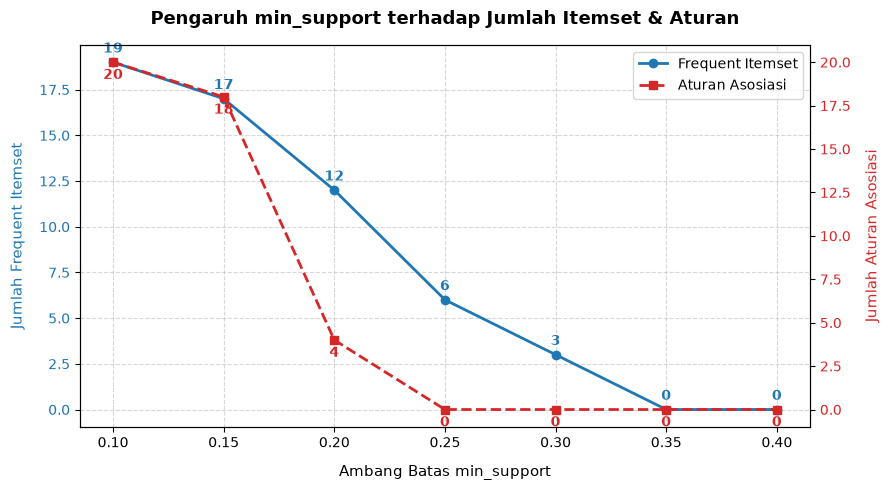

In [10]:
# Gambar 5: Grafik Pengaruh min_support
fig, ax1 = plt.subplots(figsize=(9, 5))
color1 = '#1f77b4'
ax1.set_xlabel('Ambang Batas min_support', fontsize=11, labelpad=10)
ax1.set_ylabel('Jumlah Frequent Itemset', color=color1, fontsize=11, labelpad=10)
line1 = ax1.plot(sweep_sup, itemset_counts, marker='o', color=color1, linewidth=2, label='Frequent Itemset')
ax1.tick_params(axis='y', labelcolor=color1)
for x, y in zip(sweep_sup, itemset_counts):
    ax1.annotate(f'{y}', (x, y), textcoords="offset points", xytext=(0, 7), ha='center', fontweight='bold', color=color1)

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Jumlah Aturan Asosiasi', color=color2, fontsize=11, labelpad=10)
line2 = ax2.plot(sweep_sup, rule_counts, marker='s', color=color2, linewidth=2, linestyle='--', label='Aturan Asosiasi')
ax2.tick_params(axis='y', labelcolor=color2)
for x, y in zip(sweep_sup, rule_counts):
    ax2.annotate(f'{y}', (x, y), textcoords="offset points", xytext=(0, -12), ha='center', fontweight='bold', color=color2)

plt.title('Pengaruh min_support terhadap Jumlah Itemset & Aturan', fontsize=13, fontweight='bold', pad=15)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 4.8 Eksperimen: Apriori vs FP-Growth pada min_support = 0.15
Membandingkan efisiensi waktu eksekusi algoritma Apriori (level-wise candidate generation) dengan FP-Growth (FP-Tree mining) serta memastikan bahwa keduanya menghasilkan itemset yang identik secara matematis.


In [11]:
# Benchmark Waktu Eksekusi
t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = (time.perf_counter() - t0) * 1000

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])

print(f'Apriori  : {len(freq_apriori)} itemset, {t_apriori:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth:.2f} ms')
print('Itemset identik?:', set_apriori == set_fpgrowth)


Apriori  : 17 itemset, 1.86 ms
FP-Growth: 17 itemset, 1.08 ms
Itemset identik?: True


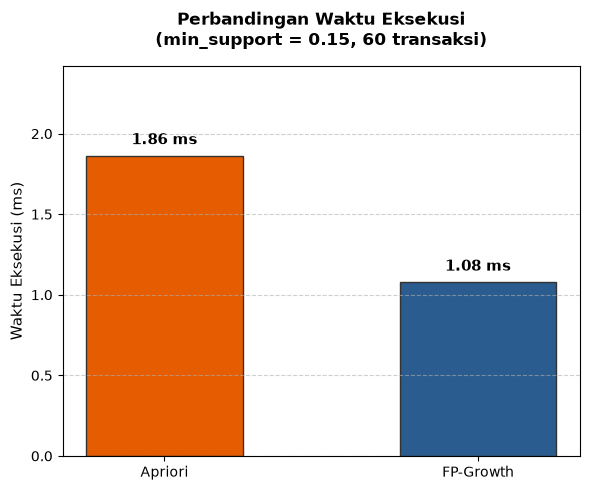

In [12]:
# Gambar 6: Grafik Perbandingan Waktu Eksekusi (min_sup = 0.15)
plt.figure(figsize=(6, 5))
bars = plt.bar(['Apriori', 'FP-Growth'], [t_apriori, t_fpgrowth], color=['#e65c00', '#2b5c8f'], width=0.5, edgecolor='#333333')
plt.title('Perbandingan Waktu Eksekusi\n(min_support = 0.15, 60 transaksi)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Waktu Eksekusi (ms)', fontsize=11)
plt.ylim(0, max(t_apriori, t_fpgrowth) * 1.3)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.05, f'{yval:.2f} ms', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
